# NLP Lab Assignment 9: Hindi POS tagging
**AI357 — Natural Language Processing, SVNIT Surat**

1. Train a Maximum Entropy Markov Model (MEMM) and evaluate it on dev/test.
2. Train a CRF with the specified features and evaluate it on dev/test.
3. Compare MEMM and CRF with Assignment 7's Naive Bayes and HMM, including per-tag F1 and bar charts.

The structure follows the supplied example. The MEMM adapts the history-based conditional architecture of the [referenced NLTK maxent POS tagger](https://github.com/arne-cl/nltk-maxent-pos-tagger), using multinomial logistic regression as in the example. It uses the required lexical features plus the preceding tag. It does not execute the original Python 2/MEGAM implementation. The CRF follows the [sklearn-crfsuite tutorial](https://sklearn-crfsuite.readthedocs.io/en/latest/tutorial.html).

Run all cells from `Lab-Assignment-9` or the repository root. Keep `Hindi-POS-Data` and the sibling `Lab-Assignment-7` directory available. All results are computed from the supplied full splits; dev and test labels are used only for evaluation.

If packages are missing, run once in a notebook cell:
```python
%pip install numpy pandas matplotlib scikit-learn sklearn-crfsuite
```


In [1]:
from pathlib import Path
from collections import Counter
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import sklearn_crfsuite

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
locations = [Path.cwd(), Path.cwd() / 'Lab-Assignment-9']
ASSIGNMENT_DIR = next((p for p in locations if (p / 'Hindi-POS-Data/hindi-train-pos.txt').is_file()), None)
if ASSIGNMENT_DIR is None:
    raise FileNotFoundError('Run from Lab-Assignment-9 or the NLP-LAB repository root.')
DATA_DIR = ASSIGNMENT_DIR / 'Hindi-POS-Data'
OUTPUT_DIR = ASSIGNMENT_DIR / 'pos_tagger_outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
print('Data directory:', DATA_DIR)


Data directory: D:\SEM5\NLP\NLP-LAB\Lab-Assignment-9\Hindi-POS-Data


## 1. Read the train, dev, and test data
Blank lines separate sentences. Every other line contains a word followed by its tag. Sentence boundaries are preserved throughout training and evaluation.


In [2]:
def read_tagged_sentences(path):
    sentences, current = [], []
    for line_number, line in enumerate(path.read_text(encoding='utf-8-sig').splitlines(), 1):
        if not line.strip():
            if current:
                sentences.append(current)
                current = []
            continue
        fields = line.rsplit(maxsplit=1)
        if len(fields) != 2:
            raise ValueError(f'{path}:{line_number}: expected word and tag')
        current.append(tuple(fields))
    if current:
        sentences.append(current)
    return sentences

datasets = {split: read_tagged_sentences(DATA_DIR / f'hindi-{split}-pos.txt')
            for split in ['train', 'dev', 'test']}
train_sents, dev_sents, test_sents = (datasets[s] for s in ['train', 'dev', 'test'])
tags = sorted({tag for sentence in train_sents for _, tag in sentence})
display(pd.DataFrame([[split, len(sentences), sum(map(len, sentences))]
                     for split, sentences in datasets.items()], columns=['Split', 'Sentences', 'Tokens']))
print('Training tag inventory:', len(tags), 'tags')
print(', '.join(tags))


,Split,Sentences,Tokens
0,train,15087,325710
1,dev,1866,40762
2,test,1910,41415


Training tag inventory: 24 tags
CC_CCD, CC_CCS, DM_DMD, JJ, N_NN, N_NNP, N_NST, PR_PRF, PR_PRL, PR_PRP, PR_PRQ, PSP, QT_QTC, QT_QTF, QT_QTO, RB, RD_PUNC, RD_SYM, RP_INJ, RP_INTF, RP_NEG, RP_RPD, V_VAUX, V_VM


## 2. Features
Each token has prefixes and suffixes of lengths 1, 2, 3, and 4. A length exceeding the word's length produces `NULL`. Context features are the previous, current, and next word, with `BOS`/`EOS` at sentence boundaries. The binary length feature is `LESS` for length ≤ 4, otherwise `MORE`.

Both models use these features. MEMM also receives the previous tag: the gold tag in training and the previous prediction in decoding. CRF learns tag transitions internally. Length is counted in Python Unicode code points, consistently with Assignment 7.


In [3]:
BOS, EOS, NULL = '<BOS>', '<EOS>', 'NULL'

def token_features(words, i, previous_tag=None):
    word = words[i]
    features = {'word=prev': words[i-1] if i else BOS,
                'word=cur': word,
                'word=next': words[i+1] if i+1 < len(words) else EOS,
                'length': 'LESS' if len(word) <= 4 else 'MORE'}
    for n in range(1, 5):
        features[f'prefix-{n}'] = word[:n] if len(word) >= n else NULL
        features[f'suffix-{n}'] = word[-n:] if len(word) >= n else NULL
    if previous_tag is not None:
        features['prev_tag'] = previous_tag
    return features

def sentence_features(sentence):
    words = [word for word, _ in sentence]
    return [token_features(words, i) for i in range(len(words))]

example_words = [word for word, _ in train_sents[0]]
display(pd.DataFrame(token_features(example_words, 0, BOS).items(), columns=['Feature', 'Value']))


,Feature,Value
0,word=prev,<BOS>
1,word=cur,यह
2,word=next,एशिया
3,length,LESS
4,prefix-1,य
5,suffix-1,ह
6,prefix-2,यह
7,suffix-2,यह
8,prefix-3,NULL
9,suffix-3,NULL


## 3. Maximum Entropy Markov Model
The locally normalized classifier estimates
$$P(t_i\mid x_i,t_{i-1})=\frac{\exp(\theta_{t_i}^{T}\phi(x_i,t_{i-1}))}{\sum_t\exp(\theta_t^{T}\phi(x_i,t_{i-1}))}.$$

`DictVectorizer` encodes categorical features, and multinomial logistic regression learns the maximum-entropy classifier. Greedy decoding predicts one tag and appends it to the history before processing the next word. Training uses the entire training split.


In [4]:
memm_rows, memm_labels = [], []
for sentence in train_sents:
    words = [word for word, _ in sentence]
    gold_tags = [tag for _, tag in sentence]
    for i, tag in enumerate(gold_tags):
        memm_rows.append(token_features(words, i, gold_tags[i-1] if i else BOS))
        memm_labels.append(tag)

memm_vectorizer = DictVectorizer(sparse=True)
X_memm = memm_vectorizer.fit_transform(memm_rows)
# SAGA requires 32-bit sparse indices; this dataset fits within that range.
X_memm.indices = X_memm.indices.astype(np.int32)
X_memm.indptr = X_memm.indptr.astype(np.int32)
memm = LogisticRegression(solver='saga', max_iter=500, tol=0.001, random_state=7)
memm.fit(X_memm, memm_labels)

def predict_memm(sentence):
    words = [word for word, _ in sentence]
    predicted = []
    for i in range(len(words)):
        previous = predicted[-1] if predicted else BOS
        row = memm_vectorizer.transform([token_features(words, i, previous)])
        predicted.append(memm.predict(row)[0])
    return predicted

print(f'MEMM training tokens: {X_memm.shape[0]:,}')
print(f'Feature columns: {X_memm.shape[1]:,}')
print('Optimizer iterations:', memm.n_iter_.tolist())


MEMM training tokens: 325,710
Feature columns: 88,753
Optimizer iterations: [33]


## 4. Conditional Random Field
The linear-chain CRF learns observation and tag-transition weights jointly and decodes the full sentence. It uses exactly the specified token features, without an explicit gold previous-tag feature. Training parameters follow the supplied tutorial: L-BFGS, L1/L2 coefficients of 0.1, 100 iterations, and all possible transitions.


In [5]:
X_crf = [sentence_features(sentence) for sentence in train_sents]
y_crf = [[tag for _, tag in sentence] for sentence in train_sents]
crf = sklearn_crfsuite.CRF(algorithm='lbfgs', c1=0.1, c2=0.1,
                          max_iterations=100, all_possible_transitions=True)
crf.fit(X_crf, y_crf)

def predict_crf(sentence):
    return crf.predict_single(sentence_features(sentence))

print('CRF training sentences:', len(X_crf))
print('CRF labels:', len(crf.classes_))


CRF training sentences: 15087
CRF labels: 24


## 5. Evaluate MEMM and CRF on dev and test
Accuracy is token accuracy. Per-tag precision, recall, and F1 use exact tag matches. Macro F1 weights all training tags equally; weighted F1 weights by gold support. Undefined precision/recall/F1 values are set to zero. No evaluation tags are supplied to either predictor.


In [6]:
def evaluate(name, predictor, sentences, split):
    y_true, y_pred = [], []
    for sentence in sentences:
        gold = [tag for _, tag in sentence]
        prediction = predictor(sentence)
        if len(prediction) != len(gold):
            raise ValueError(f'{name}: wrong prediction length')
        y_true.extend(gold)
        y_pred.extend(prediction)
    report = classification_report(y_true, y_pred, labels=tags, output_dict=True, zero_division=0)
    summary = {'split': split, 'model': name, 'accuracy': accuracy_score(y_true, y_pred),
               'macro_f1': report['macro avg']['f1-score'],
               'weighted_f1': report['weighted avg']['f1-score']}
    per_tag = [{'split': split, 'model': name, 'tag': tag,
                'precision': report[tag]['precision'], 'recall': report[tag]['recall'],
                'f1': report[tag]['f1-score'], 'support': int(report[tag]['support'])} for tag in tags]
    return summary, per_tag

summary_rows, per_tag_rows = [], []
for split in ['dev', 'test']:
    for name, predictor in [('MEMM', predict_memm), ('CRF', predict_crf)]:
        summary, per_tag = evaluate(name, predictor, datasets[split], split)
        summary_rows.append(summary)
        per_tag_rows.extend(per_tag)
        print(f'{split} {name}: accuracy={summary["accuracy"]:.4f}, macro F1={summary["macro_f1"]:.4f}')
summary_results = pd.DataFrame(summary_rows)
per_tag_results = pd.DataFrame(per_tag_rows)
display(summary_results.round(4))
summary_results.to_csv(OUTPUT_DIR / 'memm_crf_summary_metrics.csv', index=False)
per_tag_results.to_csv(OUTPUT_DIR / 'memm_crf_per_tag_metrics.csv', index=False)


dev MEMM: accuracy=0.9608, macro F1=0.9595
dev CRF: accuracy=0.9634, macro F1=0.9649
test MEMM: accuracy=0.9622, macro F1=0.9268
test CRF: accuracy=0.9645, macro F1=0.9288


,split,model,accuracy,macro_f1,weighted_f1
0,dev,MEMM,0.9608,0.9595,0.9606
1,dev,CRF,0.9634,0.9649,0.9633
2,test,MEMM,0.9622,0.9268,0.9621
3,test,CRF,0.9645,0.9288,0.9644


## 6. Compare with Assignment 7
Import the existing Assignment 7 Naive Bayes and HMM implementations, check that both assignments use the same train/dev/test sentences, and recompute their metrics. This ensures the comparison includes all four models without depending on absent CSV files. The HMM row denotes **standard forward Viterbi** from Assignment 7; no choice is made using test scores.


In [7]:
assignment7_path = ASSIGNMENT_DIR.parent / 'Lab-Assignment-7' / 'pos_tagger.py'
if not assignment7_path.is_file():
    raise FileNotFoundError(f'Assignment 7 implementation required: {assignment7_path}')
spec = importlib.util.spec_from_file_location('assignment7_baselines', assignment7_path)
assignment7 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(assignment7)
for split in ['train', 'dev', 'test']:
    original = read_tagged_sentences(assignment7_path.parent / 'Hindi-POS-Data' / f'hindi-{split}-pos.txt')
    if original != datasets[split]:
        raise ValueError(f'Assignment 7 and Assignment 9 {split} data differ')
print('All three splits match Assignment 7.')

baseline_train = [([word for word, _ in sentence], [tag for _, tag in sentence]) for sentence in train_sents]
naive_bayes = assignment7.NaiveBayes(baseline_train, tags)
hmm = assignment7.HMM(baseline_train, tags)

def predict_nb(sentence):
    return naive_bayes.predict([word for word, _ in sentence])

def predict_hmm(sentence):
    words = [word for word, _ in sentence]
    return [tags[i] for i in hmm.viterbi(hmm.emissions(words))]

for split in ['dev', 'test']:
    for name, predictor in [('Naive Bayes', predict_nb), ('HMM', predict_hmm)]:
        summary, per_tag = evaluate(name, predictor, datasets[split], split)
        summary_rows.append(summary)
        per_tag_rows.extend(per_tag)

comparison = pd.DataFrame(summary_rows)
comparison_per_tag = pd.DataFrame(per_tag_rows)
models = ['MEMM', 'CRF', 'Naive Bayes', 'HMM']
display(comparison.pivot(index='model', columns='split', values=['accuracy', 'macro_f1', 'weighted_f1'])
        .reindex(models).round(4))
comparison.to_csv(OUTPUT_DIR / 'all_model_summary_metrics.csv', index=False)
comparison_per_tag.to_csv(OUTPUT_DIR / 'all_model_per_tag_metrics.csv', index=False)

for split in ['dev', 'test']:
    print(f'{split.upper()}: per-tag F1')
    rows = comparison_per_tag[comparison_per_tag['split'] == split]
    table = rows.pivot(index='tag', columns='model', values='f1').reindex(index=tags, columns=models)
    table.insert(0, 'Support', rows[rows['model'] == 'CRF'].set_index('tag')['support'])
    display(table.round(4))


All three splits match Assignment 7.


accuracy         macro_f1         weighted_f1        
split            dev    test      dev    test         dev    test
model                                                            
MEMM          0.9608  0.9622   0.9595  0.9268      0.9606  0.9621
CRF           0.9634  0.9645   0.9649  0.9288      0.9633  0.9644
Naive Bayes   0.9102  0.9104   0.7436  0.7600      0.9079  0.9085
HMM           0.9153  0.9176   0.8541  0.8611      0.9149  0.9173

DEV: per-tag F1


model,Support,MEMM,CRF,Naive Bayes,HMM
tag,,,,,
CC_CCD,829,0.9862,0.9880,0.9598,0.9725
CC_CCS,752,0.9868,0.9848,0.9415,0.9521
DM_DMD,499,0.9545,0.9683,0.8682,0.9142
JJ,2370,0.9221,0.9257,0.8422,0.8435
N_NN,9098,0.9378,0.9413,0.8934,0.8915
N_NNP,4853,0.8840,0.8936,0.8286,0.8239
N_NST,621,0.9896,0.9936,0.9258,0.9696
PR_PRF,152,0.9967,1.0000,0.8614,0.9799
PR_PRL,106,0.9444,0.9573,0.5170,0.9016


TEST: per-tag F1


model,Support,MEMM,CRF,Naive Bayes,HMM
tag,,,,,
CC_CCD,772,0.9884,0.9865,0.9687,0.9743
CC_CCS,736,0.9919,0.9905,0.9553,0.9606
DM_DMD,516,0.9638,0.9722,0.9126,0.9228
JJ,2258,0.9270,0.9242,0.8529,0.8530
N_NN,9303,0.9385,0.9423,0.8855,0.8887
N_NNP,5296,0.8942,0.9025,0.8274,0.8322
N_NST,625,0.9888,0.9896,0.9286,0.9743
PR_PRF,151,0.9967,1.0000,0.8832,0.9832
PR_PRL,91,0.9670,0.9609,0.5323,0.9240


## 7. Bar charts
The summary plots compare overall F1 on dev and test. The two per-tag plots show all four models for every POS tag on each split. Charts are embedded here and also saved as PNG files.


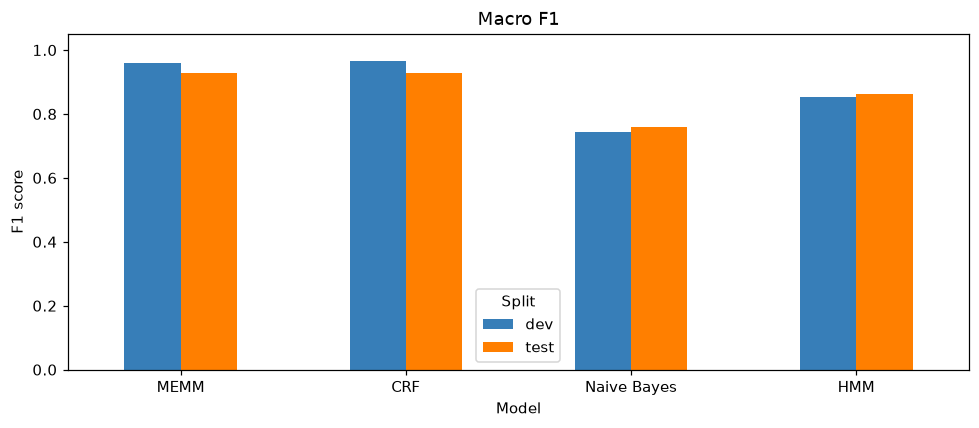

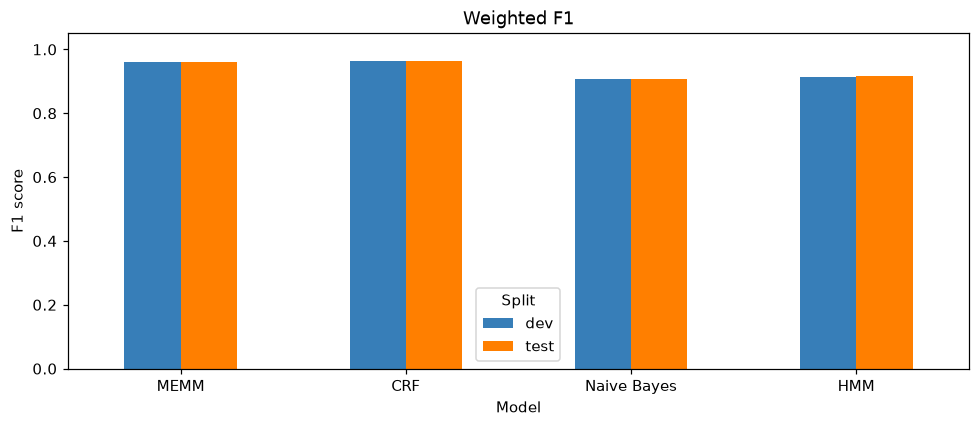

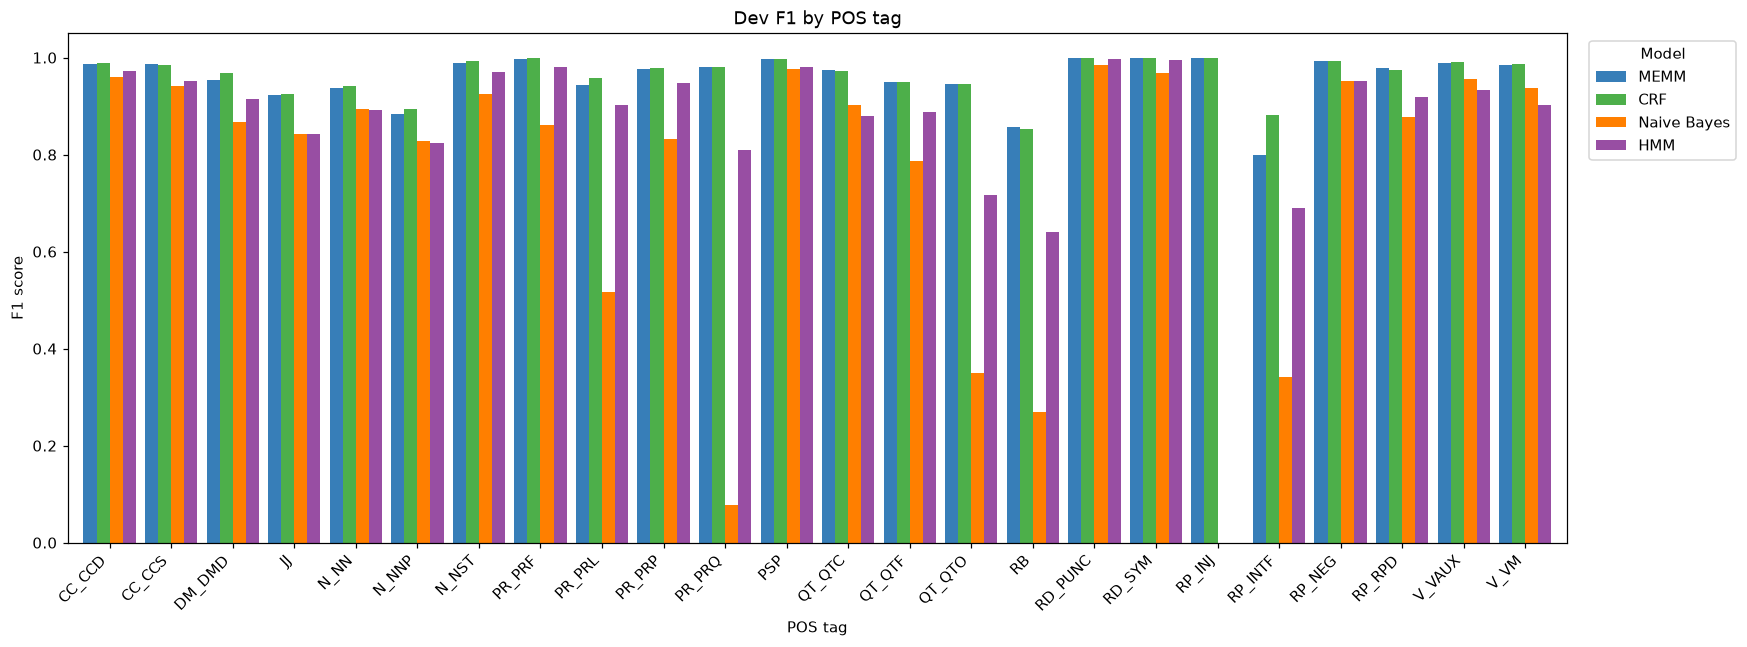

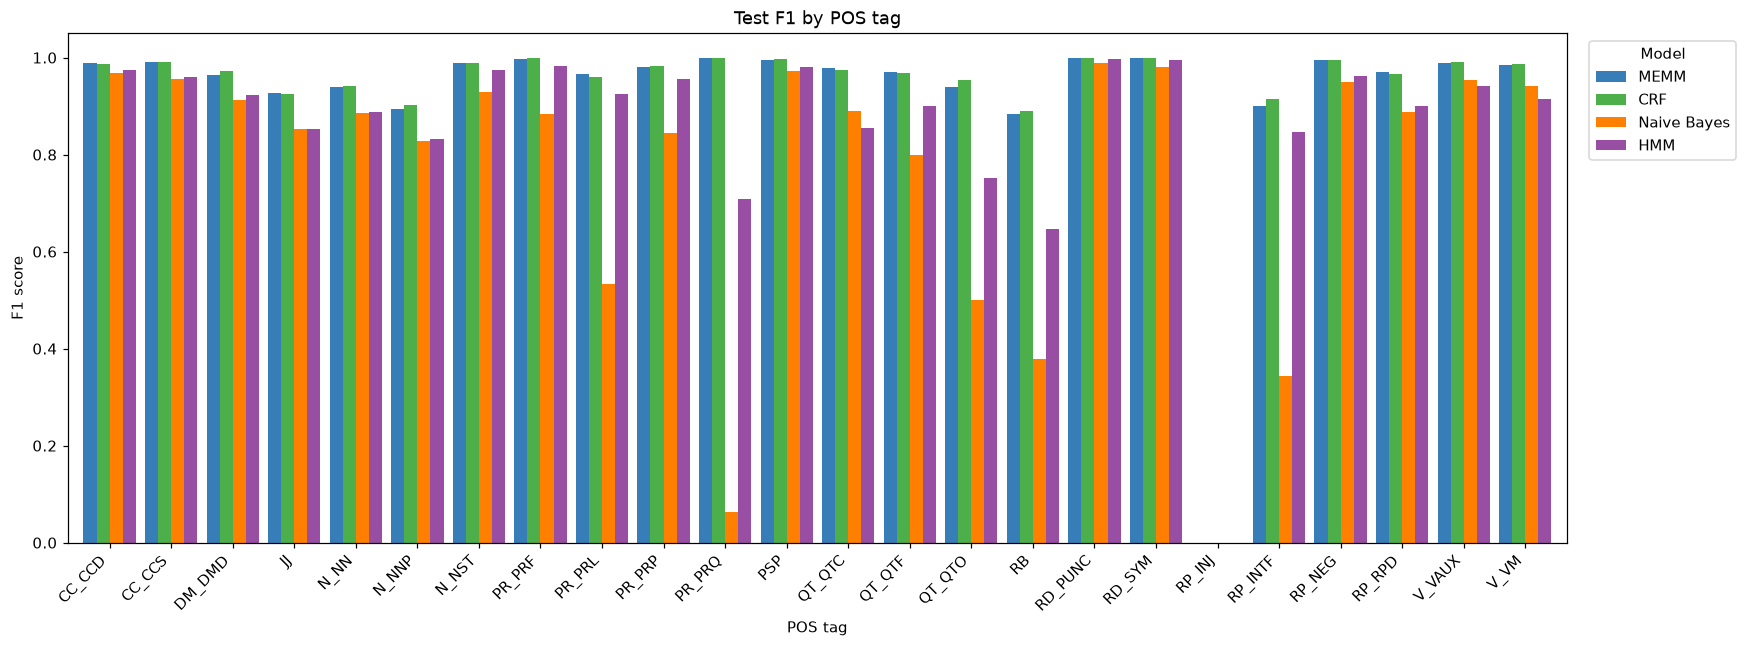

In [8]:
for metric in ['macro_f1', 'weighted_f1']:
    pivot = comparison.pivot(index='model', columns='split', values=metric).reindex(models)
    ax = pivot.plot.bar(figsize=(9, 4), ylim=(0, 1.05), rot=0,
                        title=metric.replace('_', ' ').title(), color=['#377eb8', '#ff7f00'])
    ax.set_ylabel('F1 score')
    ax.set_xlabel('Model')
    ax.legend(title='Split')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{metric}_comparison.png', dpi=150)
    plt.show()
    plt.close()

for split in ['dev', 'test']:
    rows = comparison_per_tag[comparison_per_tag['split'] == split]
    pivot = rows.pivot(index='tag', columns='model', values='f1').reindex(index=tags, columns=models)
    ax = pivot.plot.bar(figsize=(16, 6), ylim=(0, 1.05), width=0.85,
                        title=f'{split.title()} F1 by POS tag',
                        color=['#377eb8', '#4daf4a', '#ff7f00', '#984ea3'])
    ax.set_ylabel('F1 score')
    ax.set_xlabel('POS tag')
    plt.xticks(rotation=45, ha='right')
    ax.legend(title='Model', loc='upper left', bbox_to_anchor=(1.01, 1.0))
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{split}_f1_by_tag.png', dpi=150)
    plt.show()
    plt.close()


## 8. Comparative study
MEMM makes locally normalized decisions using its previous prediction, so tagging mistakes can affect later tokens. CRF jointly scores tag sequences. Naive Bayes uses Assignment 7's five features; the HMM uses learned transition and emission probabilities. These are the assigned model configurations, so score differences reflect their features as well as their modeling approaches.

The following observations are computed from the actual results. Rare tags have small supports, so their F1 can change sharply after only a few predictions; consult the support column alongside macro F1.


In [9]:
for split in ['dev', 'test']:
    summary = comparison[comparison['split'] == split].sort_values('macro_f1', ascending=False)
    best = summary.iloc[0]
    print(f'{split.upper()}: highest macro F1 is {best["model"]} ({best["macro_f1"]:.4f}).')
    print('Ranking:', ' > '.join(summary['model']))
    rows = comparison_per_tag[comparison_per_tag['split'] == split]
    table = rows.pivot(index='tag', columns='model', values='f1').reindex(columns=models)
    for model in models:
        wins = (table[model] == table.max(axis=1)).sum()
        print(f'  {model}: highest F1 on {wins}/{len(tags)} tags, counting ties.')
print('Metric tables and charts saved in:', OUTPUT_DIR)


DEV: highest macro F1 is CRF (0.9649).
Ranking: CRF > MEMM > HMM > Naive Bayes
  MEMM: highest F1 on 10/24 tags, counting ties.
  CRF: highest F1 on 19/24 tags, counting ties.
  Naive Bayes: highest F1 on 0/24 tags, counting ties.
  HMM: highest F1 on 0/24 tags, counting ties.
TEST: highest macro F1 is CRF (0.9288).
Ranking: CRF > MEMM > HMM > Naive Bayes
  MEMM: highest F1 on 12/24 tags, counting ties.
  CRF: highest F1 on 17/24 tags, counting ties.
  Naive Bayes: highest F1 on 1/24 tags, counting ties.
  HMM: highest F1 on 1/24 tags, counting ties.
Metric tables and charts saved in: D:\SEM5\NLP\NLP-LAB\Lab-Assignment-9\pos_tagger_outputs
